# Reducción de varianza en opciones asiáticas

## Paso 1. Precio exacto de la asiática geométrica

La asiática geométrica usa el promedio geométrico de los precios. Como el
producto de lognormales es lognormal, tiene fórmula cerrada: es Black-Scholes
con dos ajustes.

**Volatilidad ajustada.** El promedio se mueve menos que el precio final:

$$\sigma_a = \frac{\sigma}{\sqrt{3}}$$

**Costo de acarreo ajustado**, con $b = r - q$ (aquí $q = 0$):

$$b_a = \frac{1}{2}\left(b - \frac{\sigma^2}{6}\right)$$

**Fórmulas:**

$$d_1 = \frac{\ln(S_0/K) + (b_a + \sigma_a^2/2)T}{\sigma_a\sqrt{T}}, \qquad d_2 = d_1 - \sigma_a\sqrt{T}$$

$$C = S_0 e^{(b_a - r)T} N(d_1) - K e^{-rT} N(d_2)$$

$$P = K e^{-rT} N(-d_2) - S_0 e^{(b_a - r)T} N(-d_1)$$

Este precio será la **variable de control**: se conoce exacto y se mueve casi
igual que la asiática aritmética, que no tiene fórmula.

### Parámetros y ajustes de la asiática geométrica

In [1]:
import numpy as np
from scipy.stats import norm

S0, K, r, sigma, T = 100, 100, 0.05, 0.20, 1
q = 0
b = r - q

sigma_a = sigma / np.sqrt(3)
b_a = 0.5 * (b - sigma**2 / 6)

print(f"sigma_a = {sigma_a:.6f}")
print(f"b_a     = {b_a:.6f}")

sigma_a = 0.115470
b_a     = 0.021667


### Precio de call y put geométricas (Kemna-Vorst)

In [2]:
d1 = (np.log(S0/K) + (b_a + 0.5*sigma_a**2)*T) / (sigma_a*np.sqrt(T))
d2 = d1 - sigma_a*np.sqrt(T)

call_geo = S0*np.exp((b_a - r)*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
put_geo  = K*np.exp(-r*T)*norm.cdf(-d2) - S0*np.exp((b_a - r)*T)*norm.cdf(-d1)

print(f"d1 = {d1:.6f}   d2 = {d2:.6f}")
print(f"\nCall asiática geométrica : {call_geo:.4f}")
print(f"Put asiática geométrica  : {put_geo:.4f}")

d1 = 0.245374   d2 = 0.129904

Call asiática geométrica : 5.5468
Put asiática geométrica  : 3.4633


### Validación: paridad put-call

In [3]:
izq = call_geo - put_geo
der = S0*np.exp((b_a - r)*T) - K*np.exp(-r*T)

print(f"C - P                     : {izq:.6f}")
print(f"S0·e^((b_a-r)T) - K·e^(-rT) : {der:.6f}")

C - P                     : 2.083487
S0·e^((b_a-r)T) - K·e^(-rT) : 2.083487


### Simulación de 10 trayectorias

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

n, M = 252, 10
dt = T / n

np.random.seed(42)
Z = np.random.normal(0, 1, (M, n))
S = np.zeros((M, n + 1))
S[:, 0] = S0

for t in range(1, n + 1):
    S[:, t] = S[:, t-1] * np.exp((r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z[:, t-1])

### Media aritmética y geométrica de cada ruta

In [5]:
media_arit = S[:, 1:].mean(axis=1)
media_geo  = np.exp(np.log(S[:, 1:]).mean(axis=1))

tabla = pd.DataFrame({
    "Ruta": np.arange(M),
    "Media aritmética": media_arit,
    "Media geométrica": media_geo,
    "Diferencia": media_arit - media_geo
})
tabla.round(4)

,Ruta,Media aritmética,Media geométrica,Diferencia
0,0,93.6000,93.4301,0.1698
1,1,108.2035,107.9791,0.2243
2,2,88.0323,87.9345,0.0978
3,3,135.6060,133.7083,1.8976
4,4,126.6987,126.0398,0.6589
5,5,109.8488,109.0950,0.7538
6,6,103.9250,103.3401,0.5849
7,7,91.3297,91.2069,0.1228
8,8,95.8567,95.8281,0.0286
9,9,107.2042,107.0081,0.1961


### Gráfica de trayectorias y comparación de medias

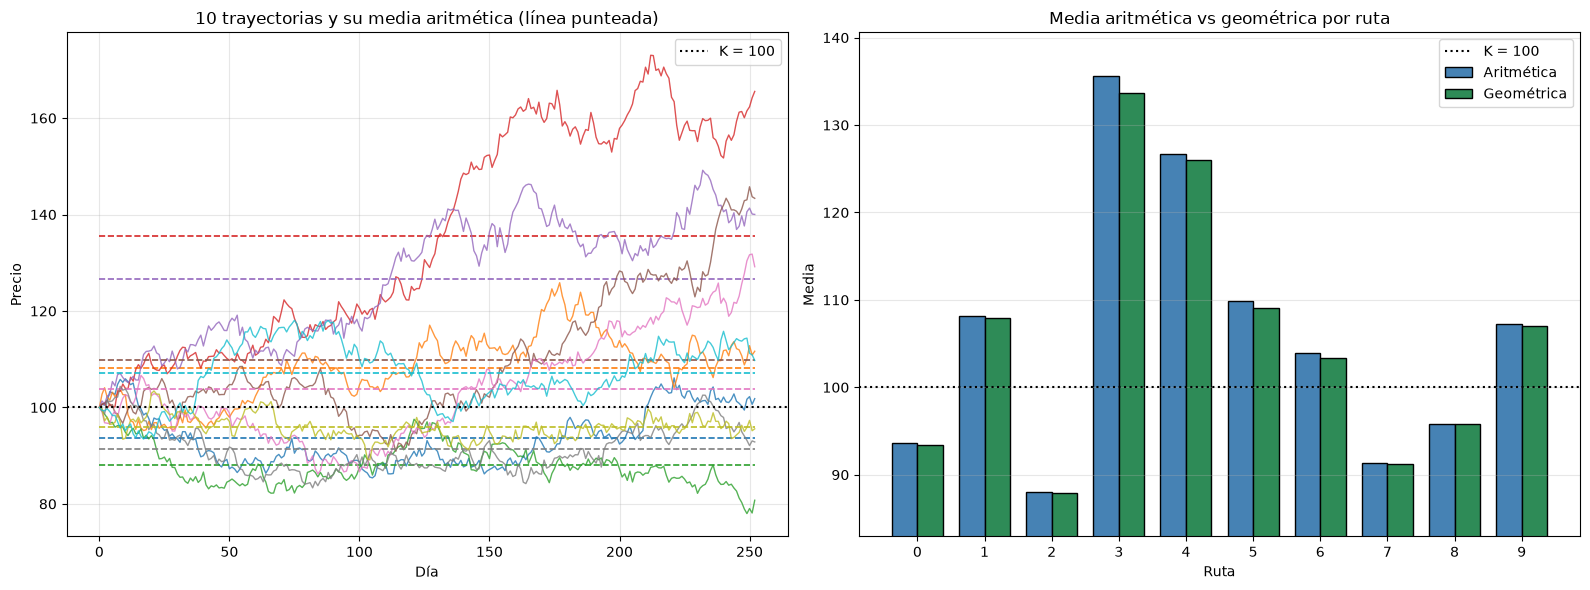

In [6]:
dias = np.arange(n + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i in range(M):
    linea, = axes[0].plot(dias, S[i], lw=1, alpha=0.8)
    axes[0].hlines(media_arit[i], 0, n, colors=linea.get_color(), ls="--", lw=1.2)

axes[0].axhline(K, color="black", ls=":", lw=1.5, label="K = 100")
axes[0].set_title("10 trayectorias y su media aritmética (línea punteada)")
axes[0].set_xlabel("Día"); axes[0].set_ylabel("Precio")
axes[0].legend(); axes[0].grid(alpha=0.3)

x = np.arange(M)
ancho = 0.38
axes[1].bar(x - ancho/2, media_arit, ancho, color="steelblue", edgecolor="black", label="Aritmética")
axes[1].bar(x + ancho/2, media_geo,  ancho, color="seagreen",  edgecolor="black", label="Geométrica")
axes[1].axhline(K, color="black", ls=":", lw=1.5, label="K = 100")
axes[1].set_ylim(min(media_geo.min(), media_arit.min()) - 5, max(media_arit.max(), media_geo.max()) + 5)
axes[1].set_xticks(x)
axes[1].set_title("Media aritmética vs geométrica por ruta")
axes[1].set_xlabel("Ruta"); axes[1].set_ylabel("Media")
axes[1].legend(); axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()